# Parte Específica: EDA Relacional e Multivariada — BankChurners

Dataset: BankChurners, arquivo tratado `out/parte_especifica/bankchurners_tratado.csv`.

Pilares cobertos neste notebook: **relacional** (correlações entre preditoras, associações numéricas e categóricas com o cancelamento `Attrition_Flag`) e **multivariado** (interações entre variáveis de comportamento e projeção PCA).

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

PASTA_SAIDA = Path("../../out/parte_especifica")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

CAMINHO_TRATADO = PASTA_SAIDA / "bankchurners_tratado.csv"
CAMINHO_BRUTO = Path("../../data/parte_especifica/BankChurners.csv")
CAMINHO_DADOS = CAMINHO_TRATADO if CAMINHO_TRATADO.exists() else CAMINHO_BRUTO

df = pd.read_csv(CAMINHO_DADOS)

# Remove identificador e colunas auxiliares de Naive Bayes caso ainda existam
cols_descartar = [c for c in df.columns if c == "CLIENTNUM" or "Naive_Bayes" in c]
if cols_descartar:
    df = df.drop(columns=cols_descartar)

COLUNA_ALVO = "Attrition_Flag"
assert COLUNA_ALVO in df.columns, f"Coluna {COLUNA_ALVO} nao encontrada."

# Flag binaria auxiliar: 1 = cancelou (Attrited Customer), 0 = ativo (Existing Customer)
if pd.api.types.is_numeric_dtype(df[COLUNA_ALVO]):
    df["cancelou"] = df[COLUNA_ALVO].astype(int)
    df["status_rotulo"] = df["cancelou"].map({0: "Existing Customer", 1: "Attrited Customer"})
else:
    df["cancelou"] = (df[COLUNA_ALVO] == "Attrited Customer").astype(int)
    df["status_rotulo"] = df[COLUNA_ALVO]

colunas_numericas = [
    c for c in df.select_dtypes(include="number").columns
    if c not in [COLUNA_ALVO, "cancelou"]
]
colunas_categoricas = [
    c for c in df.select_dtypes(exclude="number").columns
    if c not in [COLUNA_ALVO, "status_rotulo"]
]

taxa_geral = df["cancelou"].mean() * 100
print(f"Arquivo: {CAMINHO_DADOS.name} | Shape: {df.shape}")
print(f"Taxa geral de cancelamento: {taxa_geral:.2f}% ({df['cancelou'].sum()} de {len(df)})")
print(f"Numericas ({len(colunas_numericas)}): {colunas_numericas}")
print(f"Categoricas ({len(colunas_categoricas)}): {colunas_categoricas}")

Arquivo: bankchurners_tratado.csv | Shape: (10127, 22)
Taxa geral de cancelamento: 16.07% (1627 de 10127)
Numericas (14): ['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
Categoricas (5): ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']


## 1. Correlação entre variáveis numéricas (Pearson e Spearman)

Investigamos relações lineares (**Pearson**) e monotônicas (**Spearman**) entre as preditoras numéricas para identificar grupos de variáveis redundantes e indícios de multicolinearidade.

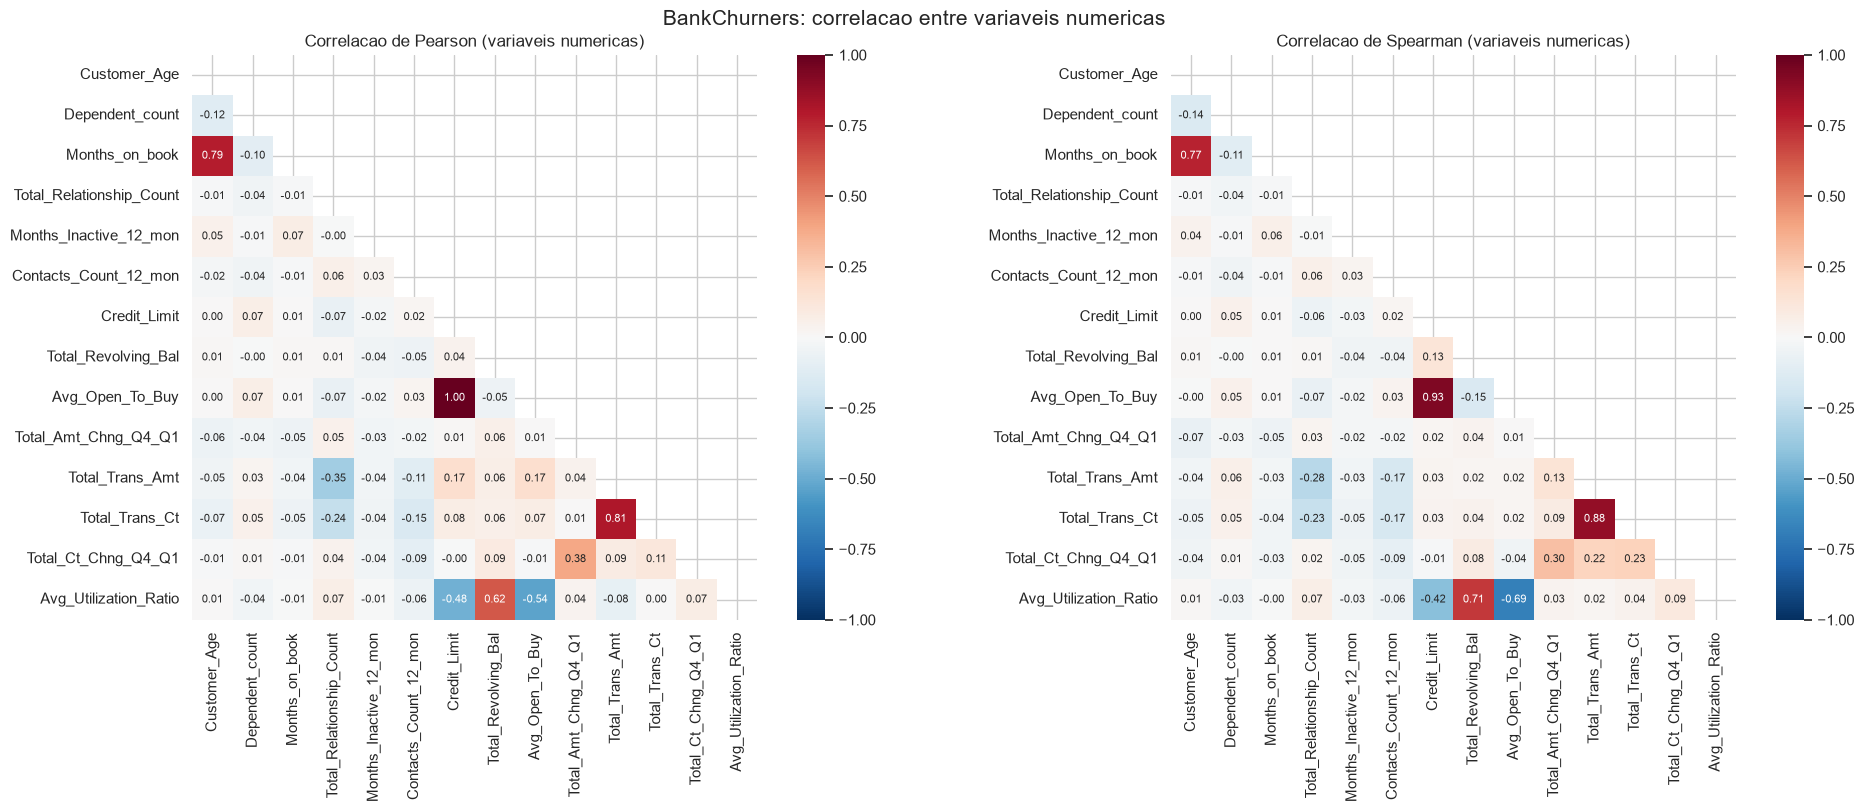

Top 12 pares de variaveis numericas por |Pearson|:


pearson  spearman  abs_pearson
Avg_Open_To_Buy       Credit_Limit                0.996     0.931        0.996
Total_Trans_Ct        Total_Trans_Amt             0.807     0.880        0.807
Months_on_book        Customer_Age                0.789     0.769        0.789
Avg_Utilization_Ratio Total_Revolving_Bal         0.624     0.709        0.624
                      Avg_Open_To_Buy            -0.539    -0.686        0.539
                      Credit_Limit               -0.483    -0.417        0.483
Total_Ct_Chng_Q4_Q1   Total_Amt_Chng_Q4_Q1        0.384     0.302        0.384
Total_Trans_Amt       Total_Relationship_Count   -0.347    -0.279        0.347
Total_Trans_Ct        Total_Relationship_Count   -0.242    -0.227        0.242
Total_Trans_Amt       Credit_Limit                0.172     0.028        0.172
                      Avg_Open_To_Buy             0.166     0.022        0.166
Total_Trans_Ct        Contacts_Count_12_mon      -0.152    -0.168        0.152

In [4]:
corr_pearson = df[colunas_numericas].corr(method="pearson")
corr_spearman = df[colunas_numericas].corr(method="spearman")
mascara = np.triu(np.ones_like(corr_pearson, dtype=bool))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(
    corr_pearson, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=axes[0]
)
axes[0].set_title("Correlacao de Pearson (variaveis numericas)")

sns.heatmap(
    corr_spearman, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=axes[1]
)
axes[1].set_title("Correlacao de Spearman (variaveis numericas)")

fig.suptitle("BankChurners: correlacao entre variaveis numericas", fontsize=15)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_correlacao.png", dpi=150, bbox_inches="tight")
plt.show()

pares = (
    corr_pearson.where(~mascara)
    .stack()
    .rename("pearson")
    .to_frame()
    .assign(spearman=corr_spearman.where(~mascara).stack())
    .assign(abs_pearson=lambda x: x["pearson"].abs())
    .sort_values("abs_pearson", ascending=False)
)
print("Top 12 pares de variaveis numericas por |Pearson|:")
display(pares.head(12).round(3))

## 2. Variáveis numéricas vs. Cancelamento (`Attrition_Flag`)

Comparamos `Existing Customer` e `Attrited Customer` em cada variável numérica usando:
- **Correlação com `cancelou`** (ponto-bisserial);
- **Tamanho de efeito $d$ de Cohen** (diferença de médias em desvios-padrão);
- **Teste de Mann-Whitney U** (não-paramétrico, robusto a assimetrias).

,media_ativos,media_cancelados,mediana_ativos,mediana_cancelados,corr_cancelou,cohen_d,p_valor_mw
variavel,,,,,,,
Total_Trans_Ct,68.67,44.93,71.00,43.00,-0.3714,-1.089,0.000000e+00
Total_Ct_Chng_Q4_Q1,0.74,0.55,0.72,0.53,-0.2901,-0.825,1.908241e-216
Total_Revolving_Bal,1256.60,672.82,1364.00,0.00,-0.2631,-0.742,1.915679e-129
Contacts_Count_12_mon,2.36,2.97,2.00,3.00,0.2045,0.569,1.110888e-80
Avg_Utilization_Ratio,0.30,0.16,0.21,0.00,-0.1784,-0.494,2.869097e-129
Total_Trans_Amt,4654.66,3095.03,4100.00,2329.00,-0.1686,-0.466,2.719009e-112
Months_Inactive_12_mon,2.27,2.69,2.00,3.00,0.1524,0.420,5.423116e-67
Total_Relationship_Count,3.91,3.28,4.00,3.00,-0.1500,-0.413,2.905717e-51
Total_Amt_Chng_Q4_Q1,0.77,0.69,0.74,0.70,-0.1311,-0.360,1.064474e-24


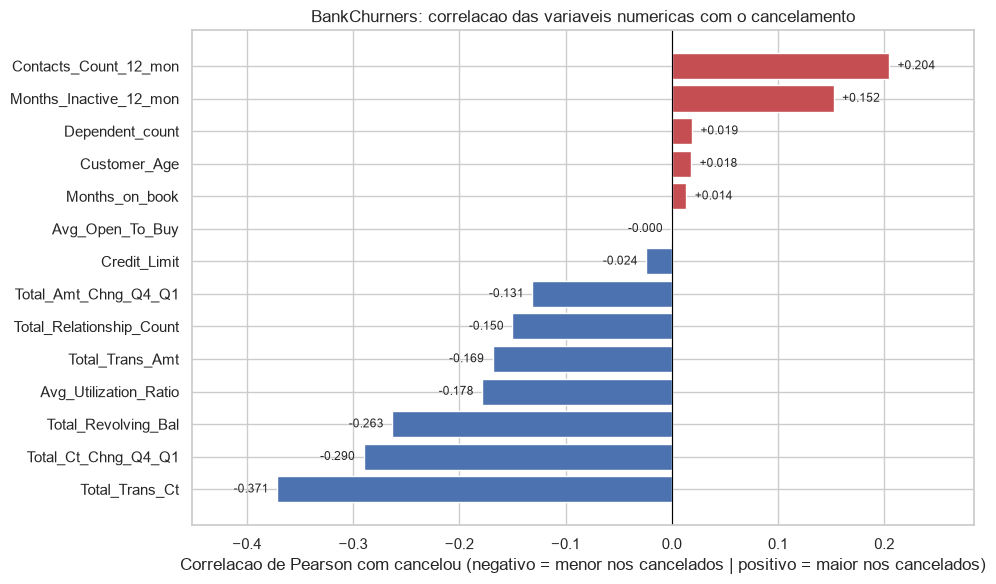

In [5]:
ativos = df[df["cancelou"] == 0]
cancelados = df[df["cancelou"] == 1]

res_num = []
for col in colunas_numericas:
    x0 = ativos[col].dropna()
    x1 = cancelados[col].dropna()
    stat, pval = mannwhitneyu(x0, x1, alternative="two-sided")
    corr_alvo = df[col].corr(df["cancelou"])
    std_pool = np.sqrt(((len(x0) - 1) * x0.var() + (len(x1) - 1) * x1.var()) / (len(x0) + len(x1) - 2))
    cohen_d = (x1.mean() - x0.mean()) / std_pool if std_pool > 0 else 0.0
    res_num.append({
        "variavel": col,
        "media_ativos": round(x0.mean(), 2),
        "media_cancelados": round(x1.mean(), 2),
        "mediana_ativos": round(x0.median(), 2),
        "mediana_cancelados": round(x1.median(), 2),
        "corr_cancelou": round(corr_alvo, 4),
        "cohen_d": round(cohen_d, 3),
        "p_valor_mw": pval,
    })

df_num_alvo = (
    pd.DataFrame(res_num)
    .assign(abs_corr=lambda x: x["corr_cancelou"].abs())
    .sort_values("abs_corr", ascending=False)
    .drop(columns=["abs_corr"])
    .set_index("variavel")
)
display(df_num_alvo)

fig, ax = plt.subplots(figsize=(10, 6))
serie_plot = df_num_alvo["corr_cancelou"].sort_values()
cores = ["#C44E52" if v > 0 else "#4C72B0" for v in serie_plot.values]
ax.barh(serie_plot.index, serie_plot.values, color=cores)
ax.axvline(0, color="black", linewidth=0.8)
for y, v in enumerate(serie_plot.values):
    ha = "left" if v >= 0 else "right"
    offset = 0.008 if v >= 0 else -0.008
    ax.text(v + offset, y, f"{v:+.3f}", va="center", ha=ha, fontsize=8.5)
ax.set_title("BankChurners: correlacao das variaveis numericas com o cancelamento")
ax.set_xlabel("Correlacao de Pearson com cancelou (negativo = menor nos cancelados | positivo = maior nos cancelados)")
ax.set_xlim(serie_plot.min() - 0.08, serie_plot.max() + 0.08)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_numericas_alvo.png", dpi=150, bbox_inches="tight")
plt.show()

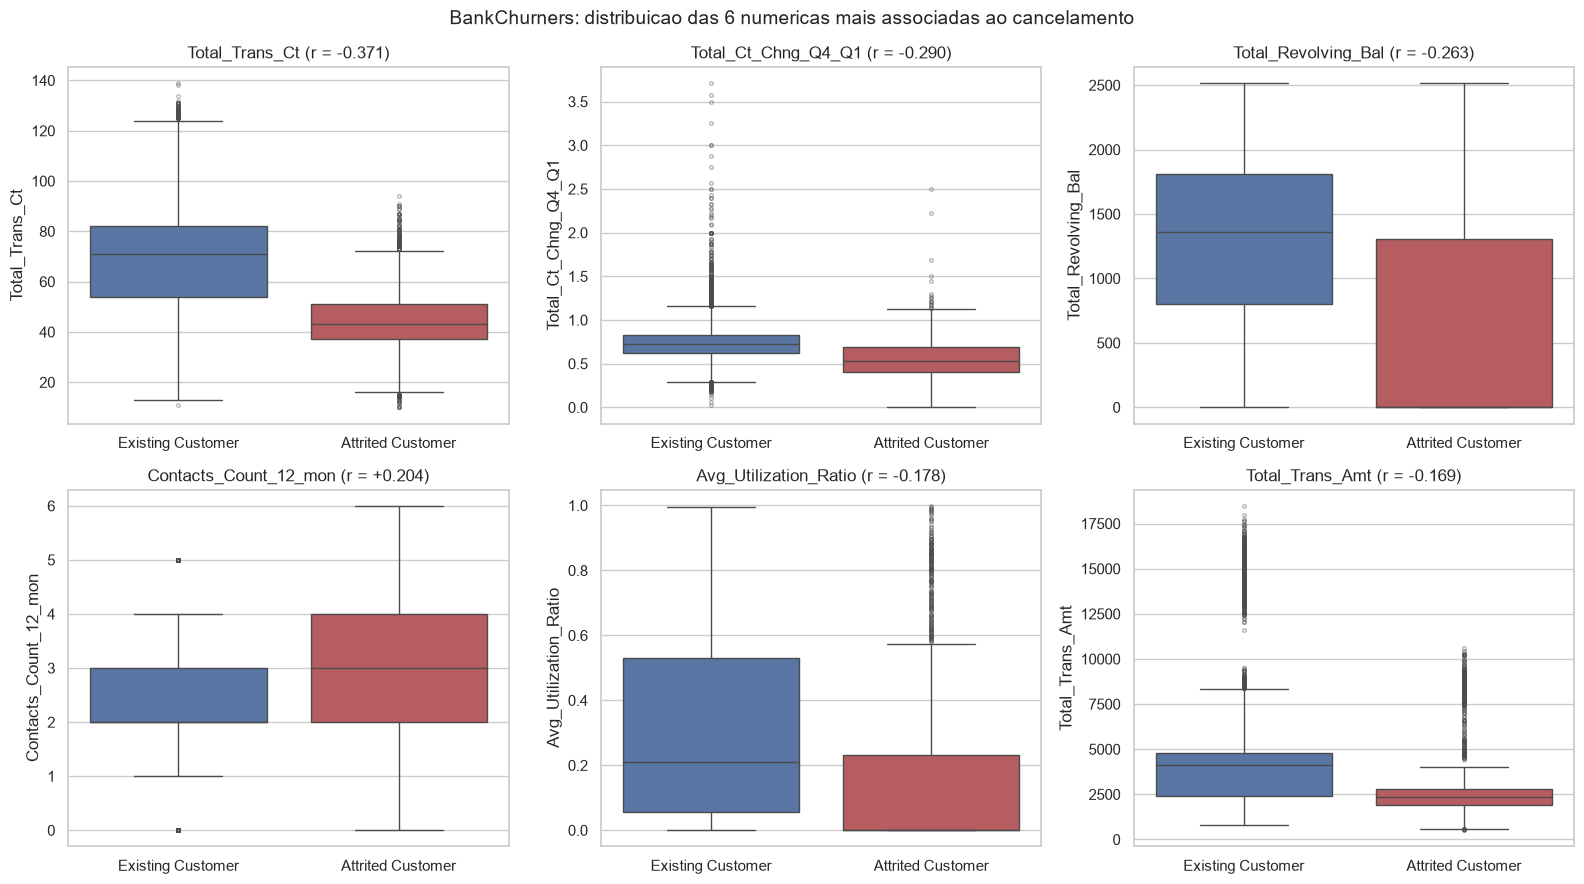

In [6]:
top6_num = df_num_alvo.index[:6].tolist()
ordem_status = ["Existing Customer", "Attrited Customer"]
paleta_status = {"Existing Customer": "#4C72B0", "Attrited Customer": "#C44E52"}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, top6_num):
    sns.boxplot(
        data=df, x="status_rotulo", y=col, order=ordem_status,
        hue="status_rotulo", palette=paleta_status, legend=False,
        flierprops={"marker": "o", "markersize": 2.5, "alpha": 0.4}, ax=ax
    )
    r_val = df_num_alvo.loc[col, "corr_cancelou"]
    ax.set_title(f"{col} (r = {r_val:+.3f})")
    ax.set_xlabel("")
    ax.set_ylabel(col)

fig.suptitle("BankChurners: distribuicao das 6 numericas mais associadas ao cancelamento", fontsize=14)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_top_numericas_alvo.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Variáveis categóricas vs. Cancelamento (`Attrition_Flag`)

Avaliamos a associação entre cada variável categórica e o cancelamento usando **Qui-Quadrado ($\chi^2$)**, **V de Cramér** e a **taxa de cancelamento (%)** por categoria comparada à média global.

,chi2,p_valor,cramers_v
variavel,,,
Gender,13.87,0.000196,0.0370
Income_Category,12.83,0.025002,0.0356
Education_Level,12.51,0.051489,0.0351
Marital_Status,6.06,0.108913,0.0245
Card_Category,2.23,0.525238,0.0149


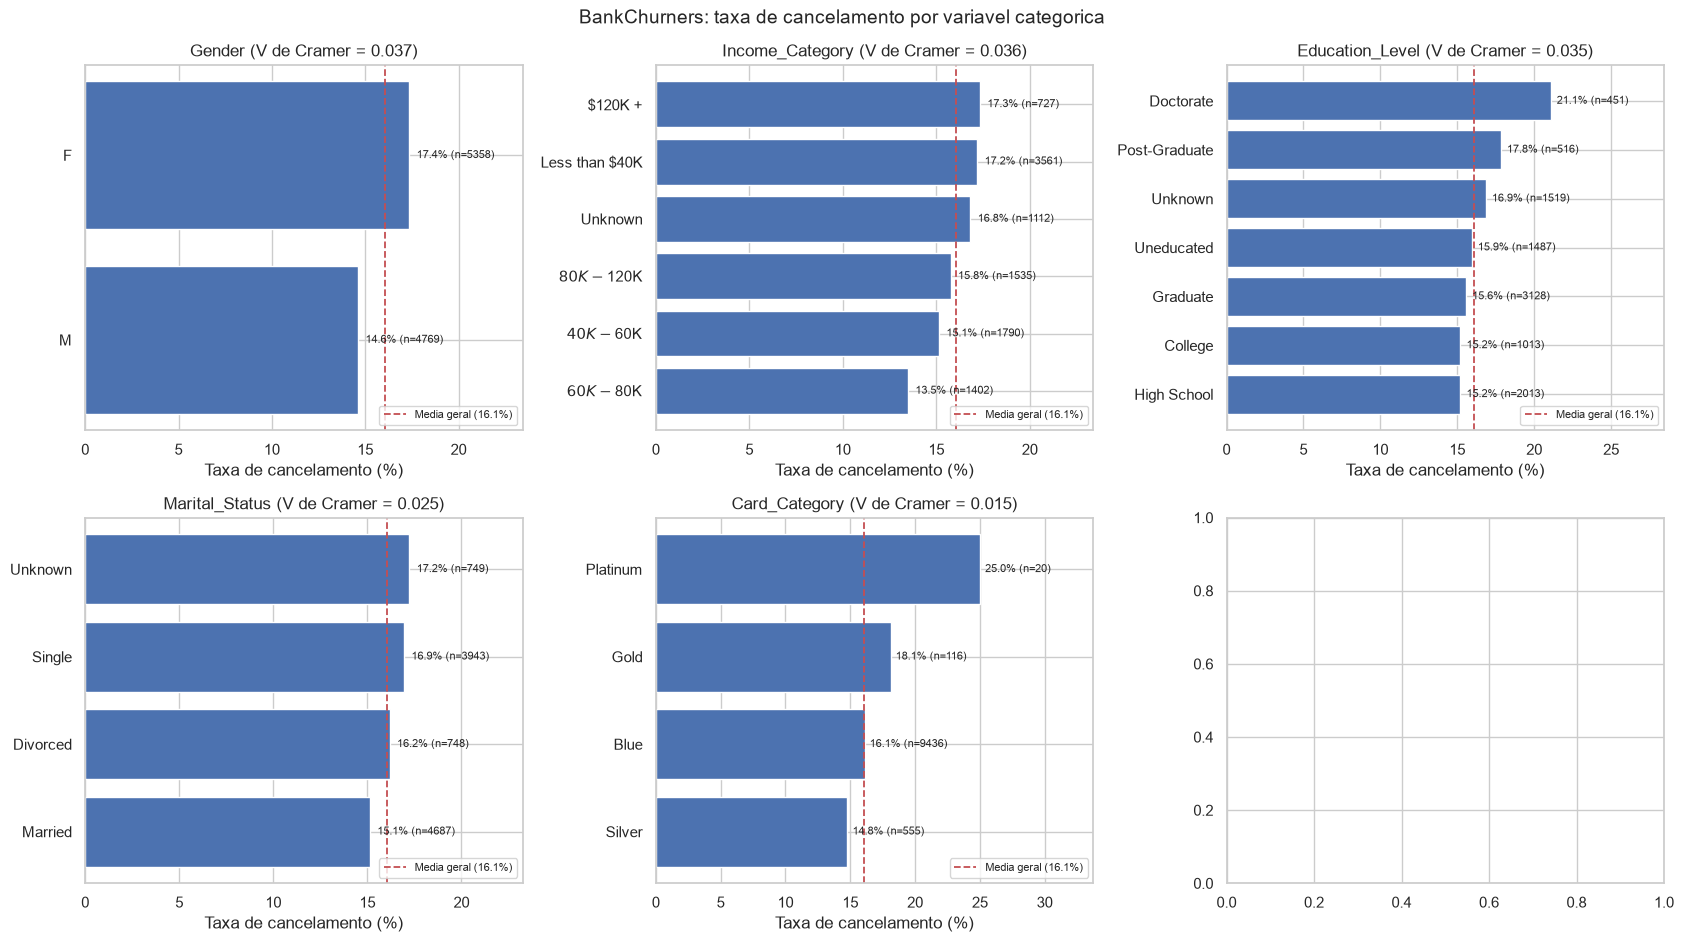

In [7]:
def cramers_v(tabela: pd.DataFrame) -> tuple[float, float, float]:
    chi2, pval, _, _ = chi2_contingency(tabela)
    n = tabela.to_numpy().sum()
    r, k = tabela.shape
    denom = n * min(r - 1, k - 1)
    v = float(np.sqrt(chi2 / denom)) if denom > 0 else 0.0
    return chi2, pval, v

res_cat = []
for col in colunas_categoricas:
    tab = pd.crosstab(df[col], df["cancelou"])
    chi2, pval, v = cramers_v(tab)
    res_cat.append({
        "variavel": col,
        "chi2": round(chi2, 2),
        "p_valor": pval,
        "cramers_v": round(v, 4),
    })

df_cramer = pd.DataFrame(res_cat).sort_values("cramers_v", ascending=False).set_index("variavel")
display(df_cramer)

n_cats = len(colunas_categoricas)
ncols = 3
nrows = int(np.ceil(n_cats / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 4.8 * nrows))
axes_flat = np.atleast_1d(axes).flat

for ax, col in zip(axes_flat, df_cramer.index):
    resumo_cat = (
        df.groupby(col, observed=True)["cancelou"]
        .agg(taxa=lambda s: s.mean() * 100, n="count")
        .sort_values("taxa")
    )
    ax.barh(resumo_cat.index.astype(str), resumo_cat["taxa"], color="#4C72B0")
    ax.axvline(taxa_geral, color="#C44E52", linestyle="--", linewidth=1.3, label=f"Media geral ({taxa_geral:.1f}%)")
    for y, (taxa, n_obs) in enumerate(zip(resumo_cat["taxa"], resumo_cat["n"])):
        ax.text(taxa + 0.4, y, f"{taxa:.1f}% (n={n_obs})", va="center", fontsize=8)
    v_val = df_cramer.loc[col, "cramers_v"]
    ax.set_title(f"{col} (V de Cramer = {v_val:.3f})")
    ax.set_xlabel("Taxa de cancelamento (%)")
    ax.set_xlim(0, max(resumo_cat["taxa"].max() * 1.35, taxa_geral * 1.4))
    ax.legend(fontsize=8, loc="lower right")

for ax in list(axes_flat)[n_cats:]:
    ax.set_visible(False)

fig.suptitle("BankChurners: taxa de cancelamento por variavel categorica", fontsize=14)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_categoricas_alvo.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Análise multivariada: interações de comportamento e PCA

Além das relações isoladas, investigamos como combinações de variáveis comportamentais separam clientes ativos e cancelados:
1. **Interação `Total_Trans_Ct × Total_Trans_Amt`** (quantidade vs. valor transacionado);
2. **Interação `Total_Trans_Ct × Total_Ct_Chng_Q4_Q1`** (volume vs. queda recente de atividade);
3. **Mapa de calor de taxa de cancelamento (%)** para `Contacts_Count_12_mon × Months_Inactive_12_mon` (atrito × inatividade);
4. **Projeção PCA (2D)** de todas as variáveis numéricas padronizadas para observar a separabilidade global.

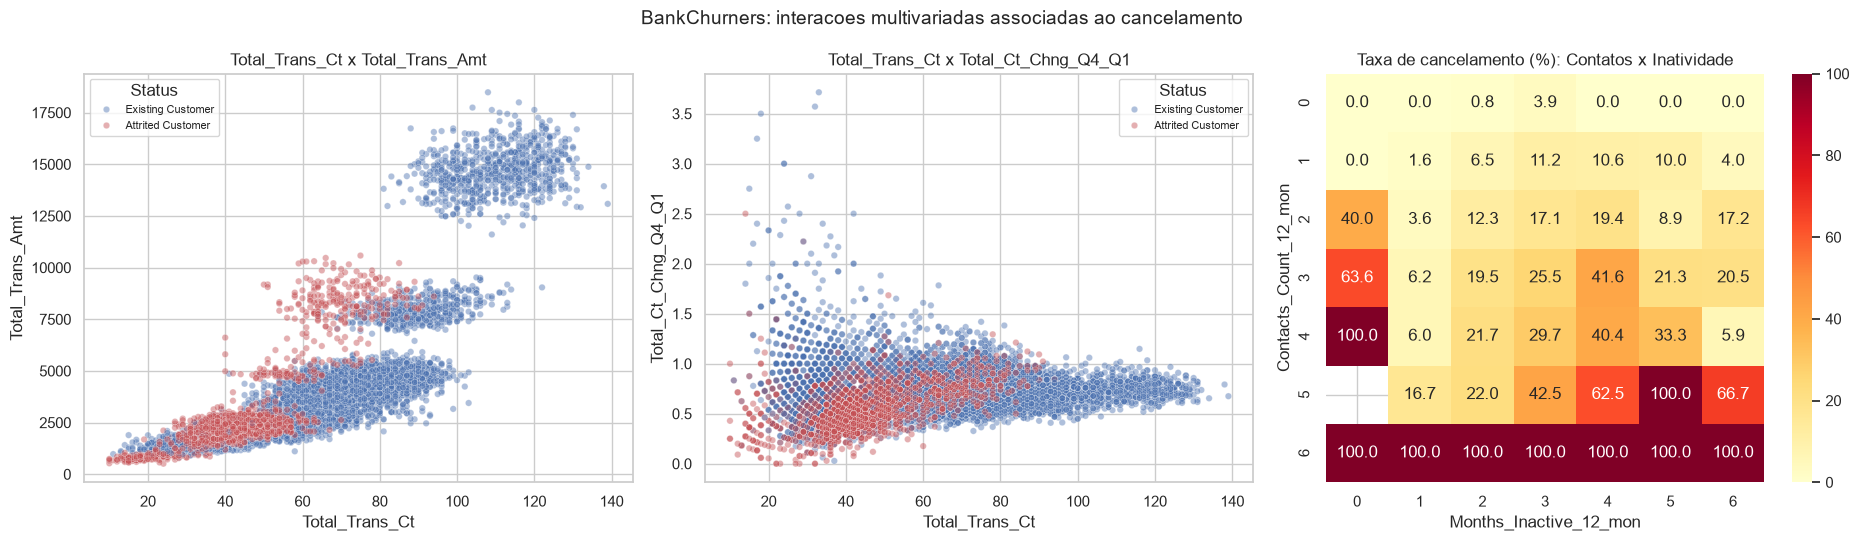

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
paleta_status = {"Existing Customer": "#4C72B0", "Attrited Customer": "#C44E52"}

# 1. Transacoes (quantidade vs valor)
if {"Total_Trans_Ct", "Total_Trans_Amt"}.issubset(df.columns):
    sns.scatterplot(
        data=df, x="Total_Trans_Ct", y="Total_Trans_Amt",
        hue="status_rotulo", hue_order=["Existing Customer", "Attrited Customer"],
        palette=paleta_status, alpha=0.45, s=22, ax=axes[0]
    )
    axes[0].set_title("Total_Trans_Ct x Total_Trans_Amt")
    axes[0].legend(title="Status", fontsize=8)

# 2. Quantidade de transacoes vs variacao Q4/Q1
if {"Total_Trans_Ct", "Total_Ct_Chng_Q4_Q1"}.issubset(df.columns):
    sns.scatterplot(
        data=df, x="Total_Trans_Ct", y="Total_Ct_Chng_Q4_Q1",
        hue="status_rotulo", hue_order=["Existing Customer", "Attrited Customer"],
        palette=paleta_status, alpha=0.45, s=22, ax=axes[1]
    )
    axes[1].set_title("Total_Trans_Ct x Total_Ct_Chng_Q4_Q1")
    axes[1].legend(title="Status", fontsize=8)

# 3. Heatmap da taxa de cancelamento: Contatos x Meses Inativos
if {"Contacts_Count_12_mon", "Months_Inactive_12_mon"}.issubset(df.columns):
    piv = df.pivot_table(
        index="Contacts_Count_12_mon",
        columns="Months_Inactive_12_mon",
        values="cancelou",
        aggfunc="mean",
    ) * 100
    sns.heatmap(piv, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[2])
    axes[2].set_title("Taxa de cancelamento (%): Contatos x Inatividade")
    axes[2].set_xlabel("Months_Inactive_12_mon")
    axes[2].set_ylabel("Contacts_Count_12_mon")

fig.suptitle("BankChurners: interacoes multivariadas associadas ao cancelamento", fontsize=14)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_multivariada_interacoes.png", dpi=150, bbox_inches="tight")
plt.show()

Variancia explicada: PC1 = 18.34% | PC2 = 14.61% | Total 2D = 32.95%


,PC1,PC2
Avg_Open_To_Buy,0.552,-0.165
Credit_Limit,0.538,-0.142
Avg_Utilization_Ratio,-0.444,0.280
Total_Trans_Amt,0.297,0.484
Total_Trans_Ct,0.231,0.509
Total_Relationship_Count,-0.174,-0.229
Total_Revolving_Bal,-0.160,0.256
Dependent_count,0.081,0.078
Customer_Age,-0.045,-0.271
Months_on_book,-0.036,-0.269


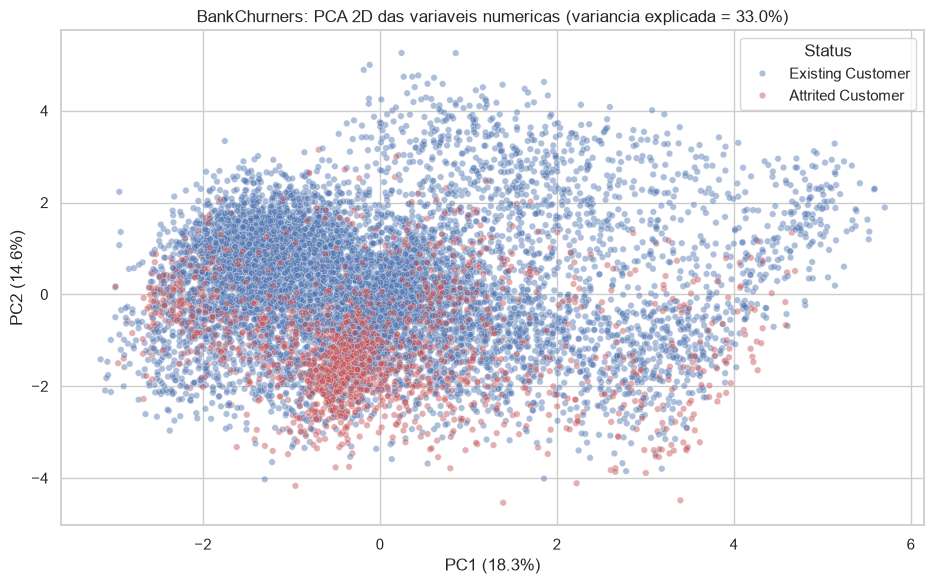

In [9]:
X_num = df[colunas_numericas].dropna()
status_pca = df.loc[X_num.index, "status_rotulo"]

X_std = StandardScaler().fit_transform(X_num)
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_std)
var_exp = pca.explained_variance_ratio_ * 100

cargas = pd.DataFrame(
    pca.components_.T,
    index=colunas_numericas,
    columns=["PC1", "PC2"]
).round(3)
print(f"Variancia explicada: PC1 = {var_exp[0]:.2f}% | PC2 = {var_exp[1]:.2f}% | Total 2D = {var_exp.sum():.2f}%")
display(cargas.sort_values("PC1", key=np.abs, ascending=False))

df_pca = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "Status": status_pca.values})
fig, ax = plt.subplots(figsize=(9.5, 6))
sns.scatterplot(
    data=df_pca, x="PC1", y="PC2", hue="Status",
    hue_order=["Existing Customer", "Attrited Customer"],
    palette={"Existing Customer": "#4C72B0", "Attrited Customer": "#C44E52"},
    alpha=0.45, s=22, ax=ax
)
ax.set_title(f"BankChurners: PCA 2D das variaveis numericas (variancia explicada = {var_exp.sum():.1f}%)")
ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_relacional_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Síntese dos achados relacionais e multivariados

1. **Multicolinearidade e variáveis derivadas:** `Credit_Limit` e `Avg_Open_To_Buy` apresentam correlação praticamente perfeita ($r \approx 0{,}996$), pois o limite disponível é derivado diretamente de `Credit_Limit - Total_Revolving_Bal`. `Total_Revolving_Bal` e `Avg_Utilization_Ratio` também têm forte relação positiva ($r \approx 0{,}62$). Além delas, destacam-se `Total_Trans_Amt × Total_Trans_Ct` ($r \approx 0{,}81$) e `Customer_Age × Months_on_book` ($r \approx 0{,}79$).
2. **Comportamento transacional domina o risco de cancelamento:** As variáveis com maior associação negativa com o churn são `Total_Trans_Ct` ($r \approx -0{,}37$), `Total_Ct_Chng_Q4_Q1` ($r \approx -0{,}29$), `Total_Revolving_Bal` ($r \approx -0{,}26$), `Avg_Utilization_Ratio` ($r \approx -0{,}18$) e `Total_Trans_Amt` ($r \approx -0{,}17$). Clientes que cancelam transacionam menos, reduzem o ritmo de uso entre Q1 e Q4 e mantêm saldo rotativo próximo de zero.
3. **Sinais positivos de atrito e desengajamento:** `Contacts_Count_12_mon` ($r \approx +0{,}20$) e `Months_Inactive_12_mon` ($r \approx +0{,}15$) têm associação positiva com o cancelamento. No heatmap multivariado, clientes que chegam a **6 contatos** em 12 meses apresentam taxa de cancelamento de 100%, e a combinação de múltiplos contatos com 3+ meses de inatividade eleva drasticamente o risco.
4. **Variáveis demográficas e categóricas têm baixo poder isolado:** Todos os valores de **V de Cramér** das categóricas (`Gender`, `Education_Level`, `Marital_Status`, `Income_Category`, `Card_Category`) ficam muito baixos ($V < 0{,}05$), confirmando que o cancelamento no `BankChurners` é explicado sobretudo por **comportamento de uso do cartão**, e não por perfil demográfico.
5. **Estrutura multivariada (PCA):** Os dois primeiros componentes explicam cerca de ~33% da variância total — `PC1` captura o eixo de limite/crédito (`Credit_Limit`, `Avg_Open_To_Buy`) e `PC2` captura engajamento/uso (`Total_Trans_Ct`, `Total_Trans_Amt`, `Total_Revolving_Bal`). Como `Attrited Customer` se concentra na região de menor atividade sem separação linear completa em 2D, combinações não-lineares de variáveis comportamentais são essenciais para distinguir os grupos.